In [75]:
import argparse
import glob
import os
import numpy as np
import awkward as ak
import matplotlib
import vector
import math
import re
import subprocess

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import Image, display
from coffea.nanoevents import NanoEventsFactory, NanoAODSchema

In [76]:
HNL_PDGID = 9900012
LEPTON_PDGID = 13
_as_int = lambda x: ak.values_astype(x, np.int64)

In [77]:
def delta_phi(a, b):
    dp = abs(a - b)
    return ak.where(dp > np.pi, 2 * np.pi - dp, dp)

In [78]:
def clip_to_range(values, bins):
    """Put underflow in the first bin and overflow in the last bin."""
    lo = bins[0]
    hi = np.nextafter(bins[-1], -np.inf)   # just below the upper edge, so it stays in the last bin
    return np.clip(values, lo, hi)
    #return np.clip(values, bins[0], bins[-1])


def to_1d(values):
    """Any (jagged / optional / numpy) array -> flat float numpy array without None/NaN/inf."""
    if not isinstance(values, np.ndarray):
        values = ak.flatten(ak.fill_none(ak.Array(values), np.nan), axis=None)
    arr = np.asarray(values, dtype=float).ravel()
    return arr[np.isfinite(arr)]


In [79]:
def match(gen, reco, max_dr):
    """
    Nearest-in-dR matching of every gen object to ONE reco collection.
    gen:  (events, ngen)   reco: (events, nreco)
    Returns (matched reco record, dR to it, boolean "inside the cone"),
    all with shape (events, ngen).
    """
    pairs = ak.cartesian({"g": gen, "r": reco}, nested=True)  # (events, ngen, nreco)
    dr = np.hypot(
        pairs.g.eta - pairs.r.eta,
        delta_phi(pairs.g.phi, pairs.r.phi),
    )
    #print('dr: ', ak.to_list(dr[:10]))
    best = ak.argmin(dr, axis=2, keepdims=True)
    #print('best: ', ak.to_list(dr[best][:10]))
    best_dr = ak.firsts(dr[best], axis=2)
    #print('bestdr: ', ak.to_list(best_dr[:10]))
    matched = ak.firsts(pairs.r[best], axis=2)
    ok = ak.fill_none(best_dr < max_dr, False)
    idx = ak.firsts(best, axis=2)
    return matched, best_dr, ok, idx



In [80]:
def match_closest(gen, reco_collections):
    """
    reco_collections: list of (name, reco, max_dr).
    Each gen muon is matched to every collection with match(); matches outside
    that collection's cone are dropped; the smallest dR wins.
    Returns chosen pt, chosen eta, source code (0 = unmatched, 1 = first
    collection, 2 = second, ...), winning dR, and a boolean "matched".
    """
    best_dr = ak.full_like(gen.pt, np.inf, dtype=float)
    out_pt = ak.full_like(gen.pt, np.nan, dtype=float)
    out_eta = ak.full_like(gen.pt, np.nan, dtype=float)
    source = ak.values_astype(ak.zeros_like(gen.pt), np.int64)
    out_idx = ak.full_like(gen.pt, -1, dtype=np.int64)
    #print('source: ', ak.to_list(source[:10]))

    for i, (name, reco, max_dr) in enumerate(reco_collections, start=1):
        matched, dr, ok, reco_idx = match(gen, reco, max_dr)
        dr = ak.where(ok, ak.fill_none(dr, np.inf), np.inf)  # drop matches outside the cone
        pt = ak.fill_none(matched.pt, np.nan)
        eta = ak.fill_none(matched.eta, np.nan)
        reco_idx = ak.fill_none(reco_idx, -1)
        
        better = dr < best_dr  # strictly closer than the current best
        #print('best_dr: ', ak.to_list(best_dr[:10]))
        best_dr = ak.where(better, dr, best_dr)
        #print('after: ', ak.to_list(best_dr[:10]))
        out_pt = ak.where(better, pt, out_pt)
        out_eta = ak.where(better, eta, out_eta)
        source = ak.where(better, i, source)
        out_idx = ak.where(better, reco_idx, out_idx)

    return out_pt, out_eta, source, best_dr, source > 0, out_idx



        

In [81]:
def flat(x, fill=np.nan):
    """(events, ngen) -> 1D numpy array, one entry per gen muon, nothing dropped."""
    return ak.to_numpy(ak.flatten(ak.fill_none(x, fill), axis=1))



In [82]:
def _drop_cartesian(name):
    return not name.endswith(("_px", "_py", "_pz"))


In [83]:
def load_events(path):
    if os.path.isdir(path):
        files = sorted(glob.glob(os.path.join(path, "*.root")))
    else:
        files = [path]
    if not files:
        raise SystemExit(f"No ROOT files found in {path}")
    chunks = []
    for f in files:
        try:
            # recent coffea
            ev = NanoEventsFactory.from_root(
                {f: "Events"}, schemaclass=NanoAODSchema,
                iteritems_options={"filter_name": _drop_cartesian},
            ).events()
        except TypeError:
            # coffea 0.7.x
            ev = NanoEventsFactory.from_root(
                f, treepath="Events", schemaclass=NanoAODSchema
            ).events()
        chunks.append(ev)
    return ak.concatenate(chunks) if len(chunks) > 1 else chunks[0]

In [84]:
# ----------------------------------------------------------------------
# plotting
# ----------------------------------------------------------------------
def plot_2d(x, y, bins, xlabel, ylabel, title, outname):
    fig, ax = plt.subplots(figsize=(6, 5))
    h = ax.hist2d(x, y, bins=bins, cmin=1)
    fig.colorbar(h[3], ax=ax, label="Events")
    ax.plot([bins[0][0], bins[0][-1]], [bins[0][0], bins[0][-1]], "r--", lw=1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{title[0]}, efficiency: {float(title[1])*100:.1f}%')
    fig.tight_layout()
    fig.savefig(outname, dpi=120)
    plt.show()
    plt.close(fig)
    #display(Image(filename=outname))



In [85]:
def plot_eff(gen_all, gen_matched, bins, xlabel, title, outname):
    n_all, _ = np.histogram(gen_all, bins=bins)
    n_mat, _ = np.histogram(gen_matched, bins=bins)
    with np.errstate(divide="ignore", invalid="ignore"):
        eff = np.where(n_all > 0, n_mat / n_all, np.nan)
        err = np.where(n_all > 0, np.sqrt(eff * (1 - eff) / n_all), np.nan)
    centers = 0.5 * (bins[1:] + bins[:-1])
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.errorbar(centers, eff, yerr=err, xerr=0.5 * np.diff(bins), fmt="o", ms=3)
    ax.set_ylim(0, 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Matching efficiency")
    ax.set_title(f'{title[0]}, efficiency: {float(title[1])*100:.1f}%')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(outname, dpi=120)
    plt.show()
    plt.close(fig)
    #display(Image(filename=outname))



In [86]:
def make_plots(label, gen, matched, ok, outdir):
    """gen: (events, ngen) gen muons; matched: records with .pt/.eta; ok: bool (events, ngen)."""
    sel = ak.to_numpy(ak.flatten(ak.fill_none(ok, False), axis=1))
    g_pt, g_eta = flat(gen.pt), flat(gen.eta)
    r_pt, r_eta = flat(matched.pt), flat(matched.eta)
    fraction = ak.sum(sel) / len(g_pt)

    pt_bins = np.linspace(0, 100, 51)
    eta_bins = np.linspace(-3, 3, 51)

    print(f"{label}: {sel.sum()} / {len(sel)} gen muons matched")

    plot_2d(g_pt[sel], r_pt[sel], (pt_bins, pt_bins),
            "gen muon $p_T$ [GeV]", "matched reco muon $p_T$ [GeV]",
            (label,f'{fraction:.3f}'), f"{outdir}/{label}_pt_gen_vs_reco.png")
    plot_2d(g_eta[sel], r_eta[sel], (eta_bins, eta_bins),
            "gen muon $\\eta$", "matched reco muon $\\eta$",
            (label,f'{fraction:.3f}'), f"{outdir}/{label}_eta_gen_vs_reco.png")
    plot_eff(g_pt, g_pt[sel], pt_bins, "gen muon $p_T$ [GeV]",
             (label,f'{fraction:.3f}'), f"{outdir}/{label}_eff_pt.png")
    plot_eff(g_eta, g_eta[sel], eta_bins, "gen muon $\\eta$",
             (label,f'{fraction:.3f}'), f"{outdir}/{label}_eff_eta.png")
    
    
    single_plot(g_pt[~sel], 51, 0, 100, f'unmatched_{label.split('_')[0]}_genpt', outdir)
    single_plot(g_eta[(~sel)], 51, -3, 3, f'unmatched_{label.split('_')[0]}_geneta', outdir)
    




In [87]:
NanoAODSchema.error_missing_event_ids = False

In [88]:
def single_plot(val, nbin, lv, hv, label, outdir):
    val = to_1d(val)
    bins = np.linspace(lv, hv, nbin)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    w = np.ones(len(val)) / max(len(val), 1)
    mean = np.mean(val) if len(val) else np.nan
    ax.hist(clip_to_range(val, bins), bins=bins, weights=w, histtype="step", lw=2,
            label=f"{label} (N={len(val)}, Mean={mean:.2f})")
    ax.set_xlabel(label)
    ax.set_ylabel("Fraction of entries")
    ax.legend()
    fig.tight_layout()
    outname = f"{outdir}/{label}.png"
    fig.savefig(outname, dpi=120)
    plt.show()
    plt.close(fig)
    #display(Image(filename=outname))


In [89]:
def double_plot(val1, val2, nbin1, nbin2,\
                lv1, lv2, hv1, hv2,\
                label1, label2, outdir, name=None):

    bins1, bins2 = np.linspace(lv1, hv1, nbin1), np.linspace(lv2, hv2, nbin2)

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))  # 1 row, 2 pads

    for ax, val, label, bins in zip(axs, (val1, val2), (label1, label2), (bins1, bins2)):
        val = to_1d(val)
        w = np.ones(len(val)) / max(len(val), 1)
        mean = np.mean(val) if len(val) else np.nan
        ax.hist(clip_to_range(val, bins), bins=bins, weights=w,
                histtype="step", lw=2, label=f"{label} (N={len(val)}, Mean={mean:.3f} cm)")
        ax.set_xlabel(label)
        ax.legend()

    axs[0].set_ylabel("Fraction of entries")   # y label only on the left pad

    fig.tight_layout()
    outname = f"{outdir}/{name or f'{label1}_{label2}'}.png"
    fig.savefig(outname, dpi=120)
    plt.show()
    plt.close(fig)
    #display(Image(filename=outname))


In [90]:
def plot_list(vals, nbin, lv, hv, labels, xlabel, outdir, title='', savename=None, vlines=None):
    """xlabel: x-axis label; savename: output file name without .png
    (defaults to xlabel with special characters replaced);
    vlines: optional list of x positions to mark with dashed vertical lines."""
    bins = np.linspace(lv, hv, nbin)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for i, val in enumerate(vals):
        val = to_1d(val)
        w = np.ones(len(val)) / max(len(val), 1)
        mean = np.mean(val) if len(val) else np.nan
        ax.hist(clip_to_range(val, bins), bins=bins, weights=w, histtype="step", lw=2,
                label=f"{labels[i]} (N={len(val)}, Mean={mean:.3f})")

    if vlines:
        cut_label = "cut: " + " - ".join(f"{x:g}" for x in vlines)
        if len(vlines) == 2:   # shade the window between two cut values
            ax.axvspan(min(vlines), max(vlines), color='red', alpha=0.12, zorder=0)
        for k, x in enumerate(vlines):
            ax.axvline(x, color='red', ls='--', lw=2, zorder=4,
                       label=cut_label if k == 0 else None)

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Fraction of entries")
    if title:
        ax.set_title(title)
    ax.legend()
    fig.tight_layout()

    if savename is None:
        savename = re.sub(r"[^A-Za-z0-9_.-]+", "_", xlabel).strip("_")
    outname = f"{outdir}/{savename}.png"
    fig.savefig(outname, dpi=120)       # saved after the title is set
    plt.close(fig)
    #display(Image(filename=outname))

In [91]:
def plot_pat_dsa_vertex_var(events, idx_p, src_p, idx_d, src_d,
                            var="displacedTrackIso03Dimuon2",
                            bins=np.linspace(0, 5, 50), outdir="plots"):
    # one gen muon per event -> one value per event
    p_idx = ak.fill_none(ak.firsts(idx_p), -1)
    d_idx = ak.fill_none(ak.firsts(idx_d), -1)
    p_src = ak.fill_none(ak.firsts(src_p), 0)
    d_src = ak.fill_none(ak.firsts(src_d), 0)

    # prompt matched to a PAT Muon AND displaced matched to a DSA muon
    ev_ok = (p_src == 1) & (d_src == 2)

    vtx = events.PatDSAMuonVertex
    is_pair = (vtx.originalMuonIdx1 == p_idx) & (vtx.originalMuonIdx2 == d_idx) & ev_ok

    print("events with prompt->Muon and displaced->DSA:", int(ak.sum(ev_ok)))
    print("  of those with a PAT-DSA vertex for this pair:", int(ak.sum(ak.any(is_pair, axis=1))))

    vals = ak.to_numpy(ak.flatten(vtx[var][is_pair], axis=None))
    #single_plot(vals, 50, 0, 5, f'PatDSAMuonVertex_{var}', outdir)
    return vals

In [92]:
def from_hnl_via_quarks(part, hnl_pdg):
    max_steps = int(ak.max(ak.num(part, axis=1)))    # longest possible chain: most particles in any event
    found = part.pt < 0
    alive = part.pt >= 0
    cur = part.parent
    steps = 0
    while ak.any(alive) and steps < max_steps:
        pid = abs(cur.pdgId)
        is_hnl = ak.fill_none(pid == hnl_pdg, False)
        is_q = ak.fill_none((pid >= 1) & (pid <= 5), False)
        found = found | (alive & is_hnl)
        alive = alive & is_q
        cur = cur.parent
        steps += 1
    return found

In [93]:
def quark_from_hnl(part):
    pid = abs(part.pdgId)
    is_quark = ak.fill_none( (pid >= 1) & (pid <= 5), False )
    last_copy = part.hasFlags(["isLastCopy"])
    has_hnlparent = ak.fill_none(part.distinctParent.pdgId == HNL_PDGID, False)
    q_fromhnl = part[is_quark & has_hnlparent & last_copy]
    pdgid = abs(q_fromhnl.distinctChildren.pdgId)
    #print(ak.any((pdgid <=5) | (pdgid >=1)))  # there are quarks from hnl which can decay to different flavour which is taken care by previous function
    return is_quark & last_copy & has_hnlparent

In [94]:
def match_quarks_to_jets(dr_q1, dr_q2, max_dr=0.4):

    results = []
    #print(dr_q1[:10])
       
    for d1, d2 in zip(
        ak.to_list(dr_q1),
        ak.to_list(dr_q2)
    ):

        d1 = np.asarray(d1)
        d2 = np.asarray(d2)

        # No reconstructed jets
        if len(d1) == 0:
            results.append({"jet1": -1, "jet2": -1, "dr1": -1.0, "dr2": -1.0})
            continue

        # Find closest jet for each quark
        idx1 = np.argmin(d1)
        idx2 = np.argmin(d2)

        # If both quarks select the same jet
        if idx1 == idx2:

            common_jet = idx1

            # Give common jet to the closer quark
            if d1[common_jet] <= d2[common_jet]:

                jet1 = common_jet
                jet2 = -1

                # Find next-closest jet for q2
                temp = d2.copy()
                temp[common_jet] = np.inf

                if np.any(np.isfinite(temp)):
                    candidate = np.argmin(temp)

                    if temp[candidate] < max_dr:
                        jet2 = candidate

            else:

                jet2 = common_jet
                jet1 = -1

                # Find next-closest jet for q1
                temp = d1.copy()
                temp[common_jet] = np.inf

                if np.any(np.isfinite(temp)):
                    candidate = np.argmin(temp)

                    if temp[candidate] < max_dr:
                        jet1 = candidate

        else:

            # Different closest jets
            jet1 = idx1
            jet2 = idx2

        # Apply deltaR requirement independently
        if jet1 >= 0 and d1[jet1] >= max_dr:
            jet1 = -1

        if jet2 >= 0 and d2[jet2] >= max_dr:
            jet2 = -1

        # Store matching distances
        dr1 = d1[jet1] if jet1 >= 0 else -1.
        dr2 = d2[jet2] if jet2 >= 0 else -1.

        results.append({
            "jet1": jet1,
            "jet2": jet2,
            "dr1": dr1,
            "dr2": dr2
        })

    return ak.Array(results)

In [95]:
vector.register_awkward()

def jet_matching(q0_vec, q1_vec, jet_vec, outputdir):
    
    # DeltaR between q1 and all reco jets
    dr_q1 = q0_vec[:, None].deltaR(jet_vec)

    # DeltaR between q2 and all reco jets
    dr_q2 = q1_vec[:, None].deltaR(jet_vec)

    matching = match_quarks_to_jets(dr_q1, dr_q2, max_dr=0.4)
    
    # ==========================================================
    # 4. EXTRACT MATCHING INFORMATION
    # ==========================================================

    jet_idx_q1 = matching['jet1']
    jet_idx_q2 = matching['jet2']

    matched_dr_q1 = matching['dr1']
    matched_dr_q2 = matching['dr2']

    # Matching flags

    q1_matched = jet_idx_q1 >= 0
    q2_matched = jet_idx_q2 >= 0

    # Number of matched quarks per event

    n_matched = (
        ak.values_astype(q1_matched, np.int32) +
        ak.values_astype(q2_matched, np.int32)
    )

    zero_matched = n_matched == 0
    one_matched = n_matched == 1
    two_matched = n_matched == 2

    print("Total events:", len(jet_vec))
    print("Zero matched events:", ak.sum(zero_matched))
    print("One matched events:", ak.sum(one_matched))
    print("Two matched events:", ak.sum(two_matched))


    
    # ==========================================================
    # 5. EXTRACT MATCHED RECO JETS
    # ==========================================================

    # Get matched reco jet four-vectors
    matched_jet_q1 = ak.Array([
        None if idx < 0 else event_jets[idx]
        for idx, event_jets in zip(
            ak.to_list(jet_idx_q1),
            ak.to_list(jet_vec)
        )
    ])

    matched_jet_q2 = ak.Array([
        None if idx < 0 else event_jets[idx]
        for idx, event_jets in zip(
            ak.to_list(jet_idx_q2),
            ak.to_list(jet_vec)
        )
    ])


    # Matched jet properties

    matched_q1_pt = matched_jet_q1.pt
    matched_q2_pt = matched_jet_q2.pt

    matched_q1_eta = matched_jet_q1.eta
    matched_q2_eta = matched_jet_q2.eta


    # ==========================================================
    # 6. PREPARE GENERATOR-LEVEL QUARK INFORMATION
    # ==========================================================

    gen_q1_pt = ak.to_numpy(q0_vec.pt)
    gen_q2_pt = ak.to_numpy(q1_vec.pt)

    gen_q1_eta = ak.to_numpy(q0_vec.eta)
    gen_q2_eta = ak.to_numpy(q1_vec.eta)

    q1_flag = ak.to_numpy(q1_matched)
    q2_flag = ak.to_numpy(q2_matched)
    
    fraction_1 = ak.sum(q1_flag)/len(gen_q1_pt)
    fraction_2 = ak.sum(q2_flag)/len(gen_q2_pt)

    #make_plots('quark', q[;,0], matched, q1matched, outdir)
    pt_bins = np.linspace(0, 100, 51)
    eta_bins = np.linspace(-3, 3, 51)
    plot_eff(gen_q1_pt, gen_q1_pt[q1_flag], pt_bins, "gen quark $p_T$ [GeV]",
             ('gen_leading_quark_matched',f'{fraction_1:.3f}'), f"{outputdir}/gen_leading_quark_eff_pt.png")
    plot_eff(gen_q2_pt, gen_q2_pt[q2_flag], pt_bins, "gen quark $p_T$ [GeV]",
             ('gen_subleading_quark_matched',f'{fraction_2:.3f}'), f"{outputdir}/gen_subleading_quark_eff_pt.png")
    
    plot_eff(gen_q1_eta, gen_q1_eta[q1_flag], eta_bins, "gen quark $\\eta$",
             ('gen_leading_quark_matched',f'{fraction_1:.3f}'), f"{outputdir}/gen_leading_quark_eff_eta.png")
    plot_eff(gen_q2_eta, gen_q2_eta[q2_flag], eta_bins, "gen quark $\\eta$",
             ('gen_subleading_quark_matched',f'{fraction_2:.3f}'), f"{outputdir}/gen_subleading_quark_eff_eta.png")
    
    
    plot_2d(gen_q1_pt[q1_flag], to_1d(matched_jet_q1.pt[q1_flag]), (pt_bins, pt_bins),
            "gen quark $p_T$ [GeV]", "matched reco jet $p_T$ [GeV]",
           ('matched_lead_quark', f'{fraction_1:.3f}'), f"{outputdir}/matched_lead_quark_pt_gen_vs_reco.png")
    
    plot_2d(gen_q2_pt[q2_flag], to_1d(matched_jet_q2.pt[q2_flag]), (pt_bins, pt_bins),
            "gen quark $p_T$ [GeV]", "matched reco jet $p_T$ [GeV]",
           ('matched_subleading_quark',f'{fraction_2:.3f}'), f"{outputdir}/matched_sublead_quark_pt_gen_vs_reco.png")
    
    plot_list([gen_q1_pt[~q1_flag], gen_q2_pt[~q2_flag]], 51, 0, 100,\
              ['unmatched leading quark', 'unmatched subleading quark'],\
              r'gen quark $p_T$ [GeV]', outputdir,
        savename='unmatched_quark_pt'
    )
    
    plot_list([gen_q1_eta[~q1_flag], gen_q2_eta[~q2_flag]], 50, -3, 3,\
              ['unmatched leading quark', 'unmatched subleading quark'],\
              r'gen quark $\eta$', outputdir,
        savename='unmatched_quark_eta'
    )


In [96]:
def calculate_decay(displaced, hnl, outputdir):
    """
    t_lab = gamma * tau            (time dilation)
    L     = beta * c * t_lab = beta * gamma * c * tau
    beta*gamma = p / (m c)
    =>  c*tau = L / (p / m)
    """
    dx = displaced.vx - hnl.vx
    dy = displaced.vy - hnl.vy
    dz = displaced.vz - hnl.vz
    lxy  = np.hypot(dx, dy)                     # transverse decay length [cm]
    L_xyz = np.sqrt(dx**2 + dy**2 + dz**2)      # 3D decay length in the lab [cm]

    p = hnl.pt * np.cosh(hnl.eta)               # |p|
    betagamma = p / hnl.mass
    ctau = L_xyz / betagamma                    # proper decay length [cm]

    double_plot(ctau, L_xyz,
                50, 50,
                0, 0,
                3 * np.mean(to_1d(ctau)), 3 * np.mean(to_1d(L_xyz)),
                'ctau', 'decay length',
                outputdir
               )
    return L_xyz


In [97]:
def plot_all(dir):

    files = sorted(f for f in glob.glob(f"{dir}/*.png")
                   if os.path.basename(f) != "all_plots.png")
    if not files:
        raise FileNotFoundError(f"no PNG files in {os.path.abspath(dir)}")
    ncols = 2
    nrows = math.ceil(len(files) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, f in zip(axes, files):
        ax.imshow(mpimg.imread(f))
        ax.set_title(os.path.basename(f), fontsize=8)
        ax.axis("off")
    for ax in axes[len(files):]:                         # hide unused cells
        ax.axis("off")

    fig.tight_layout()
    outname = os.path.join(dir, "all_plots.png")
    fig.savefig(outname, dpi=200)
    plt.close(fig)
    display(Image(filename=outname))


In [98]:
def delta_r_matrix(a, b):
    pairs = ak.cartesian({"a": a, "b": b}, nested=True)
    # event A: quark 0 paired with J0, J1, J2; quark 1 paired with J0, J1, J2   (shape 3 x 2 x njets)
    return np.hypot(pairs.a.eta - pairs.b.eta, delta_phi(pairs.a.phi, pairs.b.phi))
    # A -> [[0.071, 0.361, 2.828], [0.086, 0.206, 2.673]]
    # B -> [[0.071], [0.086]]


def _nearest(d):
    i = ak.argmin(d, axis=1, keepdims=True)
    #print('i: ', ak.to_list(i[:5]))
    # d = [[0.071, 0.361, inf], [0.071], ...]      i -> [[0], [0]]
    dist = ak.fill_none(ak.firsts(d[i], axis=1), np.inf)
    #print('dist: ', ak.to_list(dist[:5]))
    # -> [0.071, 0.071]
    idx = ak.fill_none(ak.firsts(i, axis=1), -1)
    # -> [0, 0]
    return ak.where(np.isfinite(dist), idx, -1), dist
    # d = [[inf, 0.206, inf], [inf]]  ->  idx [1, -1], dist [0.206, inf]

def valid_indices(idx):
    return ak.singletons(ak.mask(idx, idx >= 0))
    


def _jet_field(jets, idx, field):
    # jets.pt = [[11, 7, 30], [19], ...]      idx = [0, 1] (events A, B)
    sel = ak.singletons(ak.mask(idx, idx >= 0))
    # idx = [1, -1]  ->  ak.mask: [1, None]  ->  singletons: [[1], []]
    return ak.firsts(jets[field][sel], axis=1)
    # jets.pt[[[1], []]] -> [[7], []]  ->  firsts: [7.0, None]


def match_one_to_one(q, jets, max_dr):
    dr = delta_r_matrix(q, jets)
    #print(ak.to_list(dr[:5]))
    #print(ak.to_list(ak.num(jets)[:10]))
    # A: [[0.071, 0.361, 2.828], [0.086, 0.206, 2.673]]    B: [[0.071], [0.086]]
    dr = ak.where(dr < max_dr, dr, np.inf)
    # A: [[0.071, 0.361, inf], [0.086, 0.206, inf]]        B: unchanged
    dr0, dr1 = dr[:, 0], dr[:, 1]
    #print('dr0: ', ak.to_list(dr0[:5]))
    #print('dr: ', ak.to_list(dr[:5]))
    # dr0 = [[0.071, 0.361, inf], [0.071]]      dr1 = [[0.086, 0.206, inf], [0.086]]

    j0, d0 = _nearest(dr0)
    # j0 = [0, 0]      d0 = [0.071, 0.071]
    j1, d1 = _nearest(dr1)
    # j1 = [0, 0]      d1 = [0.086, 0.086]

    conflict = (j0 >= 0) & (j0 == j1)
    # -> [True, True]
    q1_loses = conflict & (d1 >= d0)
    # -> [True, True]        (0.086 >= 0.071)
    q0_loses = conflict & (d0 > d1)
    # -> [False, False]

    ids = ak.local_index(dr0, axis=1)
    #print('shape: ', ak.type(ids), '\t', ak.type(dr0), '\t', ak.type(q1_loses))
    # -> [[0, 1, 2], [0]]
    bc = lambda per_event, like: ak.broadcast_arrays(per_event, like)[0]
    #print(ak.to_list(bc(j0, dr1)[0][:10]))
    #print(ak.to_list(j0[:10]))
    #print(ak.to_list(dr1[:10]))
    # bc(q1_loses, dr1) -> [[T, T, T], [T]]        bc(j0, dr1) -> [[0, 0, 0], [0]]

    #print('q1_loses: ', ak.to_list(q1_loses[:10]))
    #print('dr1: ', ak.to_list(dr1[:10]))
    #print('bc(q1_loses, dr1): ', ak.to_list(bc(q1_loses, dr1)[:10]))
    dr1_new = ak.where(bc(q1_loses, dr1) & (ids == bc(j0, dr1)), np.inf, dr1)
    # ids == bc(j0, dr1) -> [[T, F, F], [T]]
    # -> dr1_new = [[inf, 0.206, inf], [inf]]
    dr0_new = ak.where(bc(q0_loses, dr0) & (ids == bc(j1, dr0)), np.inf, dr0)
    # -> dr0_new = dr0   (nobody to remove)

    j0, d0 = _nearest(dr0_new)
    # -> j0 = [0, 0]      d0 = [0.071, 0.071]
    j1, d1 = _nearest(dr1_new)
    # -> j1 = [1, -1]     d1 = [0.206, inf]
    #print('shape: ', ak.type(j0))
    return j0, j1, d0, d1
    # A: quark0->J0, quark1->J1      B: quark0->J0, quark1->none


def hnl_quark_genjet_matching(q, jets, max_dr=0.4):
    
    j0, j1, d0, d1 = match_one_to_one(q, jets, max_dr)
    
    # j0 = [0, 0]   j1 = [1, -1]   d0 = [0.071, 0.071]   d1 = [0.206, inf]
    assert not ak.any((j0 >= 0) & (j0 == j1)), "a jet was used twice"
    # (j0 >= 0) & (j0 == j1) -> [False, False]   -> passes

    '''
    print("both matched:", int(ak.sum((j0 >= 0) & (j1 >= 0))),
          "| only one:", int(ak.sum((j0 >= 0) ^ (j1 >= 0))),
          "| none:", int(ak.sum((j0 < 0) & (j1 < 0))))
    
    '''
    # prints: both matched: 1 | only one: 1 | none: 0
    #print('sum: ', ak.sum(ak.num(valid_indices(j0))))
    return {
        "j0": valid_indices(j0), "j1": valid_indices(j1), "d0": d0[np.isfinite(d0)], "d1": d1[np.isfinite(d1)],
        }

In [99]:
def _flat(x):
    return ak.to_numpy(ak.flatten(x, axis=None))

def in_cone(obj, jets, max_dr):
    """obj: (events,) records with eta/phi. Returns (events, njets) boolean: is obj inside the jet cone?"""
    eta = ak.broadcast_arrays(obj.eta, jets.eta)[0]       # repeat the per-event value for every jet
    phi = ak.broadcast_arrays(obj.phi, jets.phi)[0]
    return np.hypot(jets.eta - eta, delta_phi(jets.phi, phi)) < max_dr
 
def classify(daughters, jets, max_dr=0.4, fields=("pt", "eta", "phi", "mass")):
    names = list(daughters)
    for n, o in daughters.items():
        assert not ak.any(ak.is_none(o.pt)), f"daughter {n} is missing in some events"
 
    inside = {n: in_cone(o, jets, max_dr) for n, o in daughters.items()}
 
    #print('inside: ', ak.to_list(inside['q0'][:10]))
    #print('inside: ', ak.to_list(inside['q1'][:10]))
    #print('inside: ', ak.to_list(inside['l'][:10]))
    # one integer per jet: bit i is set if daughter i is inside the jet
    code = _as_int(ak.zeros_like(jets.pt))
    for i, n in enumerate(names):
        code = code + _as_int(inside[n]) * (1 << i)
 
    #print('code: ', ak.to_list(code))
    jid = ak.local_index(jets.pt, axis=1)                                 # jet index inside the event
    ev_id = ak.broadcast_arrays(ak.local_index(jets.pt, axis=0), jid)[0]  # event number, repeated per jet
    
    #print('jet: ', ak.to_list(jid[:10]))
    #print('ev_id: ', ak.to_list(ev_id[:10]))
 
    cases = {}
    for v in np.unique(_flat(code)):
        v = int(v)
        if v == 0:
            continue                                                       # jet with no daughter
        label = "+".join(n for i, n in enumerate(names) if (v >> i) & 1)
        m = code == v
        #print('m: ', ak.to_list(m[:10]))
        cases[label] = {
            "n_daughters": bin(v).count("1"),
            "count": round(int(ak.sum(m)) * 100 / len(jets), 2),
            "mask": m,                                                     # (events, njets) boolean
            "jet_idx": jid[m],                                             # jagged jet indices per event
            "pairs": np.stack([_flat(ev_id[m]), _flat(jid[m])], axis=1)   # [event, jet index]
        }
    cases = dict(sorted(cases.items(), key=lambda kv: (-kv[1]["n_daughters"], -kv[1]["count"])))
 
    stats = {
        "n_events": len(jets),
        "inside_no_jet": {n: round(int(ak.sum(ak.sum(_as_int(inside[n]), axis=1) == 0)) * 100 / len(jets), 2)
                          for n in names},
        "inside_several_jets": {n: round(int(ak.sum(ak.sum(_as_int(inside[n]), axis=1) > 1)) * 100 / len(jets) , 2)
                                for n in names},
        "contains": inside,
    }
 
    print("events:", stats["n_events"])
    print("daughters inside no jet in %:", stats["inside_no_jet"])
    print("daughters inside more than one jet in %:", stats['inside_several_jets'])
    for label, c in cases.items():
        print(f"{label:20s} {c['count']:.2f} jets in %")
    return cases, stats
 

In [100]:
def dr_between(a, b):
    return np.hypot(ak.to_numpy(a.eta) - ak.to_numpy(b.eta),
                    delta_phi(ak.to_numpy(a.phi), ak.to_numpy(b.phi)))


def dr_reco(a, b):
    """dR between two per-entry objects (missing entries allowed) -> flat numpy array."""
    return to_1d(np.hypot(a.eta - b.eta, delta_phi(a.phi, b.phi)))


In [101]:
def cone(obj, jets, max_dr):
    """obj: one gen muon per event; jets: reco muons."""

    eta = ak.broadcast_arrays(obj.eta, jets.eta)[0]
    # eta = [[0.2, 0.2], [1.0, 1.0]]

    phi = ak.broadcast_arrays(obj.phi, jets.phi)[0]
    # phi = [[0.1, 0.1], [2.0, 2.0]]

    dr = np.sqrt(
        (eta - jets.eta)**2 +
        (np.arctan2(np.sin(phi - jets.phi),
                    np.cos(phi - jets.phi)))**2
    )
    # dr = [[0.005, 0.4243],
    #       [0.0224, 0.7071]]

    dr = ak.mask(dr, dr < max_dr)
    # For max_dr = 0.01:
    # dr = [[0.005, None],
    #       [None, None]]

    idx = ak.local_index(dr, axis=1)
    # idx = [[0, 1], [0, 1]]

    minindx = ak.argmin(dr, axis=1, keepdims=True)
    # minindx = [[0], [None]]

    idx = idx[minindx]
    # idx = [[0], [None]]

    match_dr = ak.min(dr, axis=1, keepdims=True)
    # match_dr = [[0.005], [None]]

    return idx, match_dr


# Example call (inside main, where gen_mu and events exist):
# idx, match_dr = cone(ak.firsts(gen_mu, axis=1), events.Muon, 0.01)
# matched_mu = events.Muon[idx]

In [102]:
MASK_1MU = 8
MAX_DR_TRIG = 0.1
MAX_DR_DISP = 0.3

def match_objects(source, target):
    pairs_ = ak.cartesian(
        {"a": source, "b": target},
        axis=1,
        nested=True
    )
    dr = np.hypot(
        pairs_.a.eta - pairs_.b.eta,
        delta_phi(pairs_.a.phi, pairs_.b.phi)
    )

    best_idx = ak.argmin(dr, axis=2, keepdims=True)
    best_dr = ak.min(dr, axis=2, keepdims=True)

    return best_idx, best_dr

def by_pt(x):
    return x[ak.argsort(x.pt, axis=1, ascending=False)]

def get_trigger_muon(mu_all, trig_all, event_idx):

    mu = mu_all[event_idx]
    trig = trig_all[event_idx]

    trig = trig[
        (abs(trig.id) == 13) &
        ((trig.filterBits & MASK_1MU) == MASK_1MU)
    ]

    _, trig_dr = match_objects(mu, trig)

    trig_match_dr = ak.firsts(trig_dr, axis=2)

    is_trig = ak.fill_none(
        trig_match_dr < MAX_DR_TRIG,
        False
    )

    return is_trig


def select_prompt_displaced(mu_ev, is_trig, l):
    """
    1) prompt muon = leading trigger-matched reco muon
    2) displaced muon = reco muon closest to gen displaced l (dR < MAX_DR_DISP),
       searched among the remaining reco muons
    3) efficiency = displaced matched / entries with a triggered prompt muon
    """
    ids = ak.local_index(mu_ev, axis=1)
    prompt_i = ak.firsts(ids[is_trig], axis=1)     # first trigger-matched muon = highest pT
    has_trig = ~ak.is_none(prompt_i, axis=0)
    prompt_i = ak.fill_none(prompt_i, -1)
    m_trig = ak.firsts(mu_ev[ak.singletons(ak.mask(prompt_i, has_trig))], axis=1)

    rest = mu_ev[ids != prompt_i]
    lep = ak.singletons(l)
    disp_idx, disp_dr = match_objects(lep, rest)
    best_dr = ak.firsts(ak.firsts(disp_dr, axis=1), axis=1)     # one value per entry
    disp_i  = ak.firsts(ak.firsts(disp_idx, axis=1), axis=1)
    has_disp = ak.fill_none(best_dr < MAX_DR_DISP, False) & has_trig
    m_disp = ak.firsts(rest[ak.singletons(ak.mask(disp_i, has_disp))], axis=1)

    trig_np = ak.to_numpy(has_trig)
    keep = ak.to_numpy(has_disp)
    disp_eff = ak.sum(has_disp) / max(int(ak.sum(has_trig)), 1)
    return has_trig, has_disp, m_trig, m_disp, trig_np, keep, disp_eff


Mass:10, V^2:6.3e-07, ctau:0.690cm
['genPartIdxMother', 'statusFlags', 'pdgId', 'status', 'eta', 'mass', 'phi', 'pt', 'iso', 'genPartIdxMotherG', 'distinctParentIdxG', 'childrenIdxG', 'distinctChildrenIdxG', 'distinctChildrenDeepIdxG']
events: 2149
daughters inside no jet in %: {'q0': 59.7, 'q1': 77.01, 'l': 70.96}
daughters inside more than one jet in %: {'q0': 0.56, 'q1': 0.37, 'l': 0.33}
q0+q1+l              5.12 jets in %
q0+q1                13.40 jets in %
q0+l                 11.96 jets in %
q1+l                 2.70 jets in %
q0                   10.38 jets in %
l                    9.59 jets in %
q1                   2.14 jets in %
triggered (>=1 trigger-matched muon):  0.43636363636363634
triggered prompt:  0.43636363636363634 	 displaced reco efficiency (given trigger):  0.7291666666666666
displaced muon matched in 0.7291666666666666
q0+q1, triggered prompt: 0.4236111111111111	 displaced reco efficiency (given trigger): 0.5
q0+l, displaced reco efficiency (given trigger): 0.

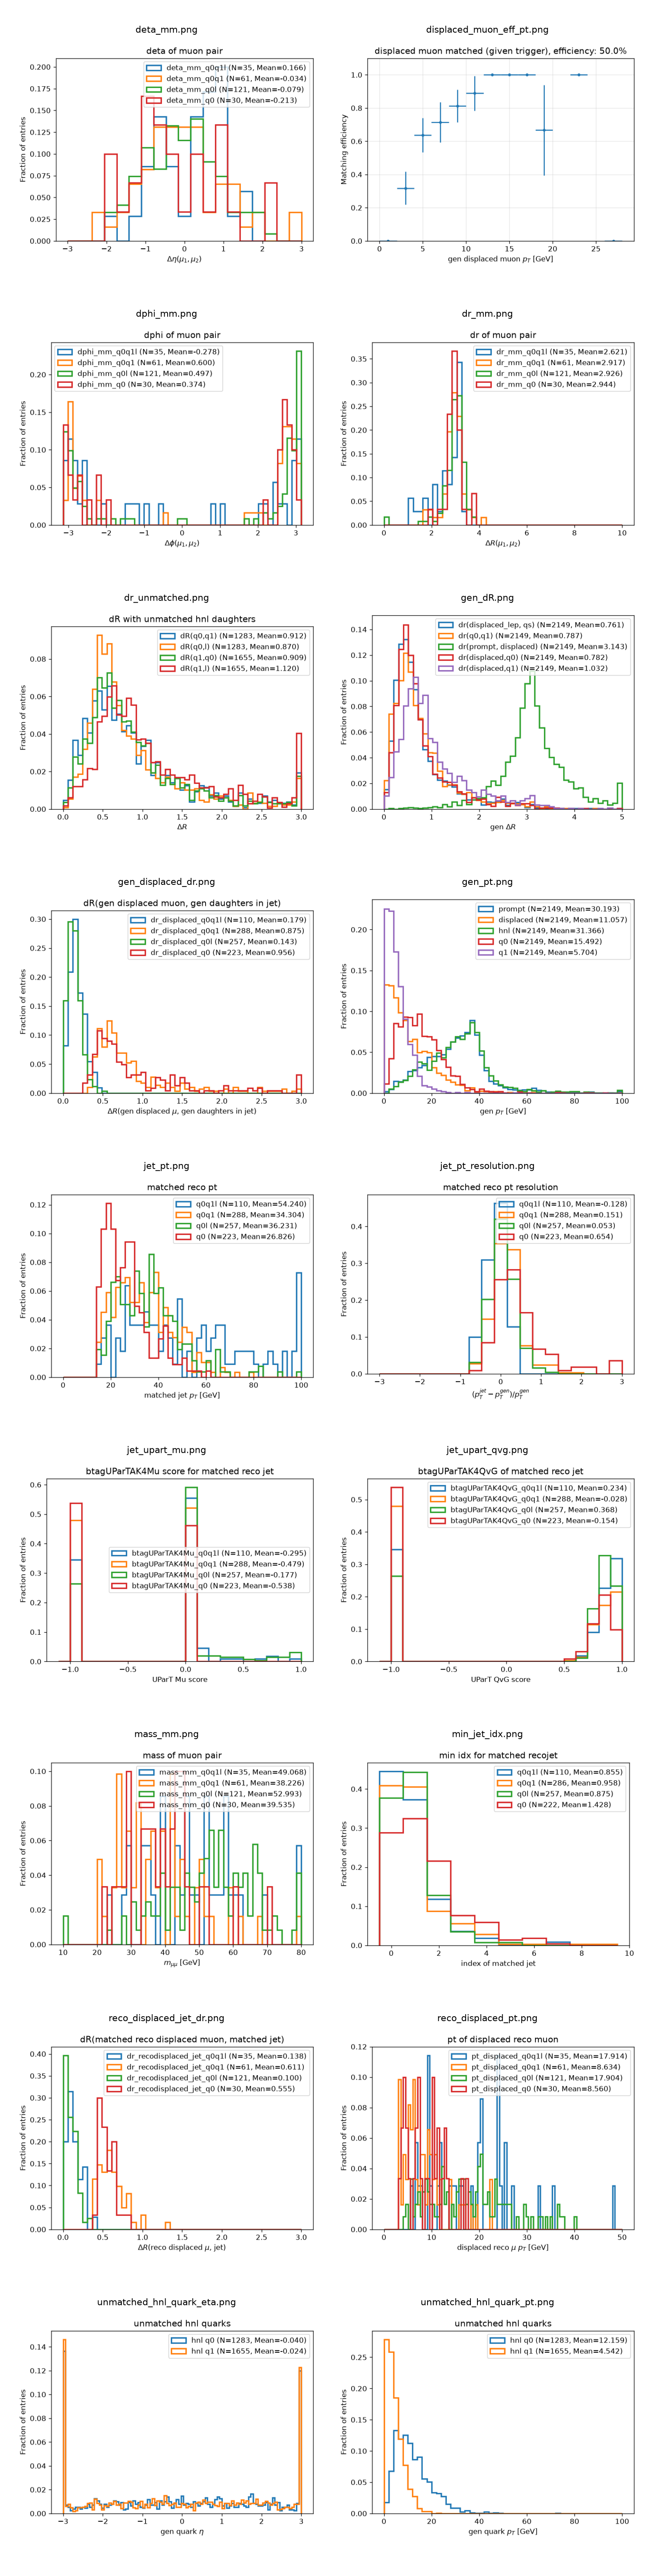

Mass:10, V^2:2.17e-08, ctau:20.025cm
['genPartIdxMother', 'statusFlags', 'pdgId', 'status', 'eta', 'mass', 'phi', 'pt', 'iso', 'genPartIdxMotherG', 'distinctParentIdxG', 'childrenIdxG', 'distinctChildrenIdxG', 'distinctChildrenDeepIdxG']
events: 2000
daughters inside no jet in %: {'q0': 77.5, 'q1': 87.45, 'l': 83.8}
daughters inside more than one jet in %: {'q0': 0.25, 'q1': 0.1, 'l': 0.1}
q0+q1+l              3.80 jets in %
q0+l                 6.35 jets in %
q0+q1                6.05 jets in %
q1+l                 0.95 jets in %
q0                   6.55 jets in %
l                    5.20 jets in %
q1                   1.85 jets in %
triggered (>=1 trigger-matched muon):  0.42105263157894735
triggered prompt:  0.42105263157894735 	 displaced reco efficiency (given trigger):  0.6875
displaced muon matched in 0.6875
q0+q1, triggered prompt: 0.39669421487603307	 displaced reco efficiency (given trigger): 0.14583333333333334
q0+l, displaced reco efficiency (given trigger): 0.63492063492

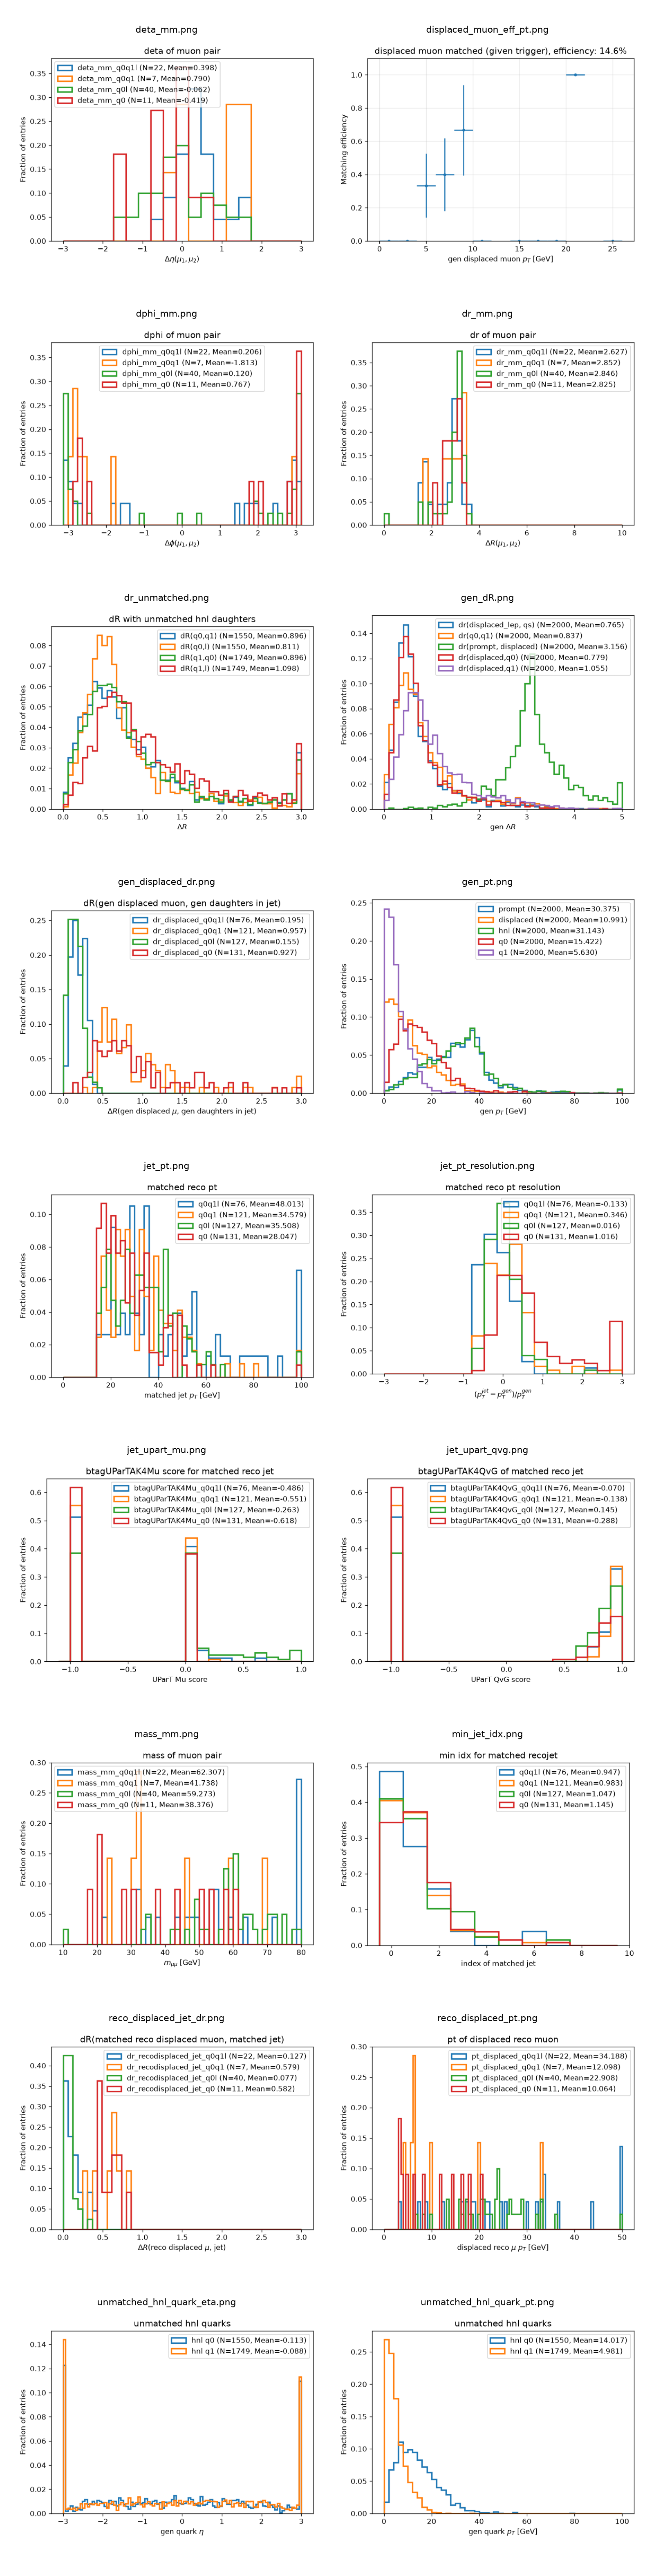

Mass:14, V^2:1.99e-07, ctau:0.381cm
['genPartIdxMother', 'statusFlags', 'pdgId', 'status', 'eta', 'mass', 'phi', 'pt', 'iso', 'genPartIdxMotherG', 'distinctParentIdxG', 'childrenIdxG', 'distinctChildrenIdxG', 'distinctChildrenDeepIdxG']
events: 2064
daughters inside no jet in %: {'q0': 63.23, 'q1': 84.3, 'l': 73.93}
daughters inside more than one jet in %: {'q0': 0.34, 'q1': 0.24, 'l': 0.29}
q0+q1+l              1.11 jets in %
q0+q1                10.76 jets in %
q0+l                 7.66 jets in %
q1+l                 1.55 jets in %
q0                   17.59 jets in %
l                    16.04 jets in %
q1                   2.52 jets in %
triggered (>=1 trigger-matched muon):  0.391304347826087
triggered prompt:  0.391304347826087 	 displaced reco efficiency (given trigger):  0.8888888888888888
displaced muon matched in 0.8888888888888888
q0+q1, triggered prompt: 0.45495495495495497	 displaced reco efficiency (given trigger): 0.5544554455445545
q0+l, displaced reco efficiency (given

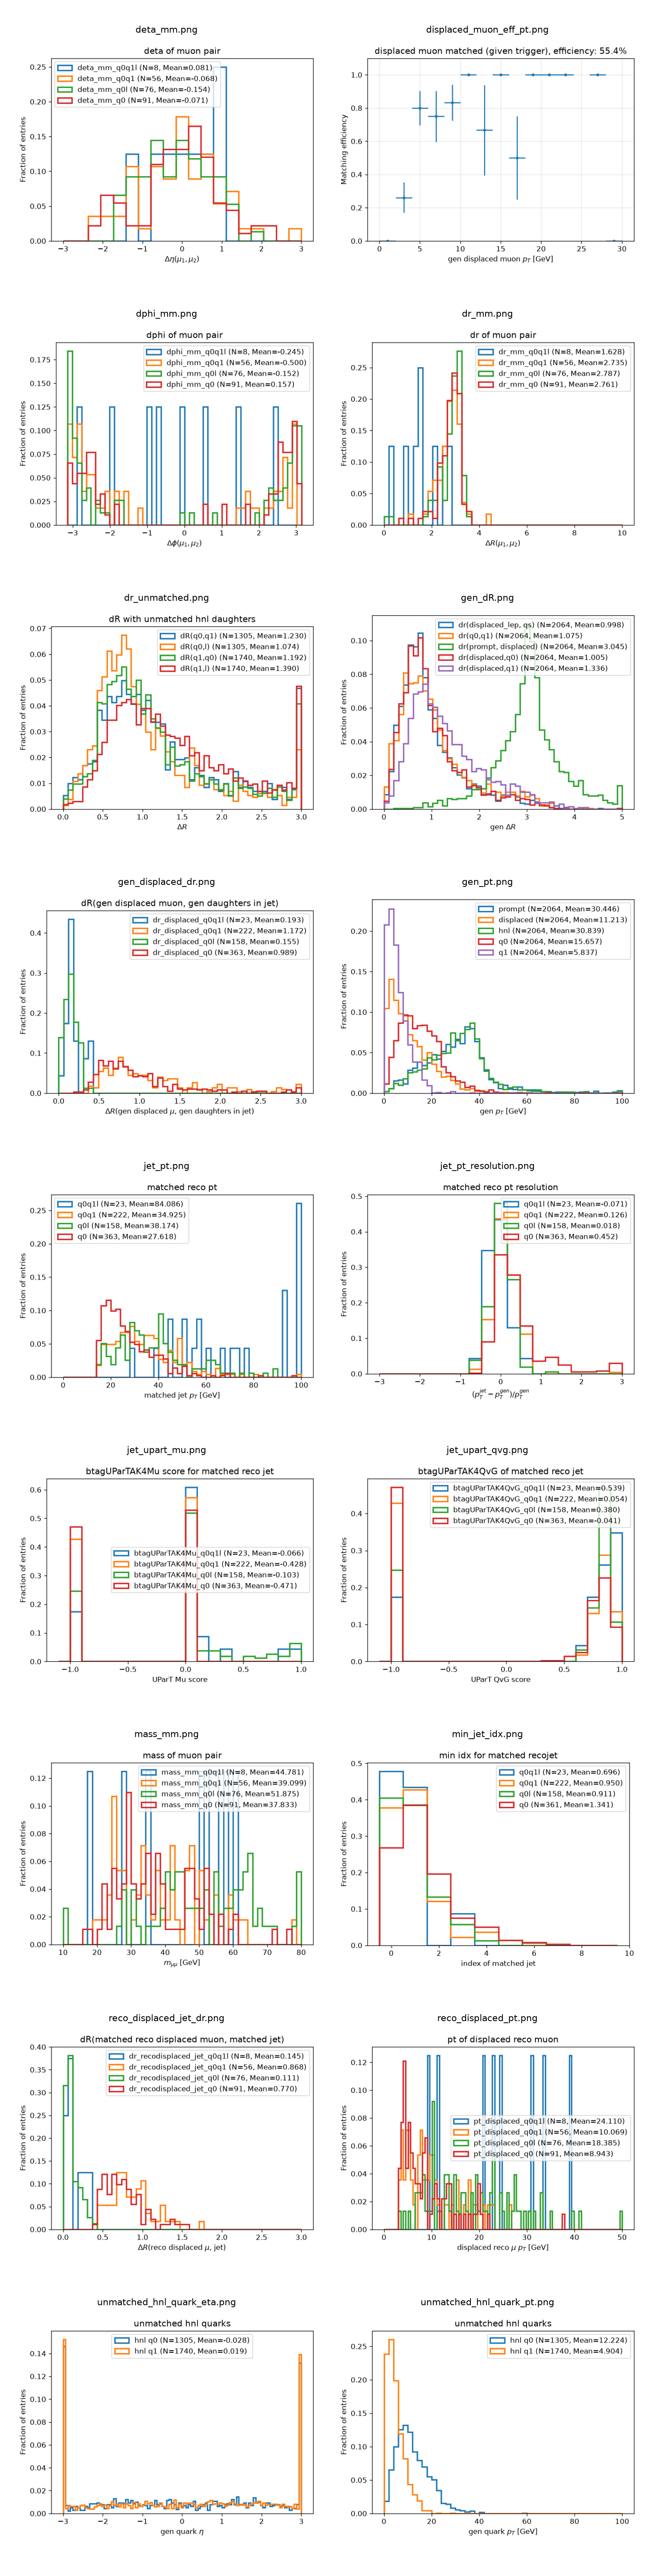

In [108]:
def main(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("input", help="flat NanoAOD file or directory")
    p.add_argument("--out", default="plots")
    p.add_argument("--max-dr", type=float, default=0.1, help="dR cut for Muon")
    p.add_argument("-d", "--dsa-collection", default=None,
                   help="name of DSA muon collection, e.g. DSAMuon")
    p.add_argument("--dsa-max-dr", type=float, default=0.3)
    p.add_argument("--per-collection", action="store_true",
                   help="also make separate plots for each reco collection")
    p.add_argument("--title", type=str, default='')
    
    args = p.parse_args(argv)
    os.makedirs(args.out, exist_ok=True)

    events = load_events(args.input)
    #print(events.fields)
    gen = events.GenPart
    
    w = gen[(abs(gen.pdgId)==24) & gen.hasFlags('isHardProcess')]
    w_pt = flat(w.pt)
    w_p = flat(w.pt * np.cosh(w.eta))
    w_p = w_p[np.isfinite(w_p)]

    # gen muons: last copy
    gen_mu = gen[(abs(gen.pdgId) == LEPTON_PDGID) & gen.hasFlags(["isLastCopy"])]
    hnl = gen[(gen.pdgId == HNL_PDGID) & gen.hasFlags(["isLastCopy"])]

    # displaced: first ancestor with a different pdgId is the HNL
    parent = gen_mu.distinctParent
    is_displaced = ak.fill_none(abs(parent.pdgId) == HNL_PDGID, False)

    # prompt: from hard process and not from the HNL
    prompt = gen_mu[gen_mu.hasFlags(["fromHardProcess"]) & ~is_displaced]
    displaced = gen_mu[is_displaced]
    assert len(events) == int(ak.sum(ak.num(prompt))) == int(ak.sum(ak.num(displaced))), \
        "expected exactly one prompt and one displaced gen muon per event"

    # gen muon pt: prompt vs displaced
    prompt_pt = flat(prompt.pt)
    displaced_pt = flat(displaced.pt)
    hnl_pt = flat(hnl.pt)
    hnl_p = flat(hnl.pt * np.cosh(hnl.eta))
    print(displaced.fields)
    #L_xyz = calculate_decay(displaced, hnl, args.out)
    
    
    # Select W and HNL
  
    w_pz = w.pt * np.sinh(w.eta)
    w_energy = np.sqrt(
    w.pt**2 * np.cosh(w.eta)**2 + w.mass**2
    )

    hnl_pz = hnl.pt * np.sinh(hnl.eta)
    hnl_energy = np.sqrt(
    hnl.pt**2 * np.cosh(hnl.eta)**2 + hnl.mass**2
    )
    w_pz_one = ak.firsts(w_pz, axis=1)
    w_energy_one = ak.firsts(w_energy, axis=1)

    hnl_pz_one = ak.firsts(hnl_pz, axis=1)
    hnl_energy_one = ak.firsts(hnl_energy, axis=1)

    beta = w_pz_one / w_energy_one
    gamma = 1 / np.sqrt(1 - beta**2)

    hnl_px_star = ak.firsts(hnl.pt * np.cos(hnl.phi), axis=1)
    hnl_py_star = ak.firsts(hnl.pt * np.sin(hnl.phi), axis=1)
    hnl_pz_star = gamma * (
        hnl_pz_one - beta * hnl_energy_one
    )

    hnl_p_star = np.sqrt(
        hnl_px_star**2 + hnl_py_star**2 + hnl_pz_star**2
    )

    #print(events.fields)
    '''
    costheta = hnl_pz_star / hnl_p_star
    costheta_np = ak.to_numpy(costheta)
    costheta_valid = costheta_np[np.isfinite(costheta_np)]
    single_plot(costheta_valid, 50, -1, 1,
            "cosTheta_HNL", args.out)
    print("W eta NaN:", ak.sum(~np.isfinite(w.eta)))
    print("W pt zero:", ak.sum(w.pt == 0))
    print("W mass NaN:", ak.sum(~np.isfinite(w.mass)))

    print("HNL eta NaN:", ak.sum(~np.isfinite(hnl.eta)))
    print("HNL pt zero:", ak.sum(hnl.pt == 0))
    print("W mass:", ak.to_list(w.mass[:10]))
    print("W pt:", ak.to_list(w.pt[:10]))
    print("W eta:", ak.to_list(w.eta[:10]))
    print("W pz:", ak.to_list(w_pz[:10]))
    print("W energy:", ak.to_list(w_energy[:10]))
    print("W status:", ak.to_list(w.status[:10]))
    print("W statusFlags:", ak.to_list(w.statusFlags[:10]))
    print("W mass:", ak.to_list(w.mass[:10]))
    assert(0)'''
    #gen quark
    #is_quark = lambda x: (abs(x) >= 1) & (abs(x) <= 5)
    #q = gen[is_quark(gen.pdgId) # & gen.hasFlags(["isLastCopy"])
    #   & from_hnl_via_quarks(gen, HNL_PDGID)]
    
    #print(ak.mean(hnl.pt), ak.mean(hnl.pt * np.cosh(hnl.eta)))      # HNL pT and p
    #h = ak.firsts(hnl)
    #q_fromhnl = gen[quark_from_hnl(gen)]
    #n = ak.num(q_fromhnl, axis=1)
    #print('min: ', ak.min(n), '\t', ak.max(n))
    #assert ak.all(ak.num(q_fromhnl, axis=1) == 2), "not every event has exactly 2 quarks"
    #print(ak.min(ak.num(q)), '\t', ak.max(ak.num(q)))
    #assert ak.all(ak.num(q, axis=1) == 2), "not every event has exactly 2 quarks"
    
    is_quark = lambda pid: (abs(pid) >= 1) & (abs(pid) <= 5)
    daughters = hnl.children                                             # shape (events, nhnl, ndaughters)
    q_direct = ak.flatten(daughters[is_quark(daughters.pdgId)], axis=1)
    assert ak.all(ak.num(q_direct, axis=1) == 2), 'quark from hnl is not 2'    
    q_sorted = q_direct[ak.argsort(q_direct.pt, axis=1, ascending=False)]
    plot_list([prompt_pt, displaced_pt, hnl_pt, q_sorted[:,0].pt, q_sorted[:,1].pt],
              51, 0, 100,
              ['prompt', 'displaced', 'hnl', 'q0', 'q1'],
              r'gen $p_T$ [GeV]', args.out,
        savename='gen_pt'
    )
    
    has_vtx = all(f in gen.fields for f in ("vx", "vy", "vz"))
    if has_vtx:
        calculate_decay(displaced, hnl, args.out)
    
    vector.register_awkward()

    q0_vec = ak.zip(
        {
            "pt": q_sorted[:,0].pt,
            "eta": q_sorted[:,0].eta,
            "phi": q_sorted[:,0].phi,
            "mass": q_sorted[:,0].mass
        },
        with_name="Momentum4D"
    )

    q1_vec = ak.zip(
        {
            "pt": q_sorted[:,1].pt,
            "eta": q_sorted[:,1].eta,
            "phi": q_sorted[:,1].phi,
            "mass": q_sorted[:,1].mass
        },
        with_name="Momentum4D"
    )

    lep_vec = ak.zip(
        {
            "pt": displaced.pt,
            "eta": displaced.eta,
            "phi": displaced.phi,
            "mass": displaced.mass
        },
        with_name="Momentum4D"
    )
    
    prompt_vec = ak.zip(
        {
            "pt": prompt.pt,
            "eta": prompt.eta,
            "phi": prompt.phi,
            "mass": prompt.mass
        },
        with_name="Momentum4D"
    )
    # Dijet four-momentum
    dijet = q1_vec + q0_vec

    # Dijet-lepton angular separation
    dr_lepq = lep_vec.deltaR(dijet)
    dr_q0q1 = q0_vec.deltaR(q1_vec)
    dr_ll   = lep_vec.deltaR(prompt_vec)
    dr_lq0  = lep_vec.deltaR(q0_vec)
    dr_lq1  = lep_vec.deltaR(q1_vec)

    # Dijet invariant mass
    mjj = dijet.mass
    
    plot_list([dr_lepq, dr_q0q1, dr_ll, dr_lq0, dr_lq1],
              50, 0, 5,
             ['dr(displaced_lep, qs)', 'dr(q0,q1)', 'dr(prompt, displaced)', 'dr(displaced,q0)', 'dr(displaced,q1)'],
             r'gen $\Delta R$', args.out,
        savename='gen_dR'
    )
    
    
    genjet = events.GenJet
    recojet = events.Jet #ak.singletons(ak.firsts(events.Jet, axis=1))
    recolepton = events.Muon
    recolepton_vec = ak.zip(
        {
            "pt": recolepton.pt,
            "eta": recolepton.eta,
            "phi": recolepton.phi,
            "mass": recolepton.mass
        },
        with_name="Momentum4D"
    )
    
    mu_all = events.Muon
    trig_all = events.TrigObj
    
    if 1:
        studyjet = recojet
        studyjet_vec = ak.zip(
        {
            "pt": studyjet.pt,
            "eta": studyjet.eta,
            "phi": studyjet.phi,
            "mass": studyjet.mass
        },
            with_name="Momentum4D"
        )
        studylepton = recolepton
        studylepton_vec = recolepton_vec
    #genjetmatch = hnl_quark_genjet_matching(q_sorted, recojet)
    
    #plot_list([flat(genjet[genjetmatch['j0']].pt), q_sorted[:,0].pt],
    #          51, 0, 100, ['jet', 'hnl_quark'],
    #          'pt', args.out, 'quark_to_recojet_match')
    
    cases, stats = classify({'q0': q_sorted[:,0], 'q1': q_sorted[:,1],
                             'l': ak.firsts(displaced,axis=1)}, studyjet
                           )
  

    empty = np.array([])
    min_jetidx_q0q1l = min_jetidx_q0q1 = min_jetidx_q0l = min_jetidx_q0 = empty
    displaced_pt_q0q1l = displaced_pt_q0q1 = displaced_pt_q0l = displaced_pt_q0 = empty
    dr_l_q0q1l = dr_l_q0q1 = dr_l_q0l = dr_l_q0 = empty
    dr_recodisp_jet_q0q1l = dr_recodisp_jet_q0q1 = dr_recodisp_jet_q0l = dr_recodisp_jet_q0 = empty   # NEW
    mass_mm_q0q1l = mass_mm_q0q1 = mass_mm_q0l = mass_mm_q0 = empty
    dr_mm_q0q1l = dr_mm_q0q1 = dr_mm_q0l = dr_mm_q0 = empty
    deta_mm_q0q1l = deta_mm_q0q1 = deta_mm_q0l = deta_mm_q0 = empty
    dphi_mm_q0q1l = dphi_mm_q0q1 = dphi_mm_q0l = dphi_mm_q0 = empty
    reco_displaced_pt_q0q1l = reco_displaced_pt_q0q1 = reco_displaced_pt_q0l = reco_displaced_pt_q0 = empty
    btagUParTAK4QvG_q0q1l = btagUParTAK4QvG_q0q1 = btagUParTAK4QvG_q0l = btagUParTAK4QvG_q0 = empty
    btagUParTAK4Mu_q0q1l = btagUParTAK4Mu_q0q1 = btagUParTAK4Mu_q0l = btagUParTAK4Mu_q0 = empty
    pt_res_q0q1l = pt_res_q0q1 = pt_res_q0l = pt_res_q0 = empty
    matched_jet_pt_q0q1l = matched_jet_pt_q0q1 = matched_jet_pt_q0l = matched_jet_pt_q0 = empty

    #q0+q1+l
    if "q0+q1+l" in cases:
        pairs = cases["q0+q1+l"]["pairs"]
        event_idx = pairs[:, 0]
        jet_idx = pairs[:, 1]
        jetidx = cases["q0+q1+l"]["jet_idx"]
        min_jetidx_q0q1l = ak.min(jetidx, axis=1)
    
        is_trig = get_trigger_muon(mu_all, trig_all, event_idx)
        print('triggered (>=1 trigger-matched muon): ', ak.sum(ak.any(is_trig, axis=1))/len(event_idx))
        mu_ev = mu_all[event_idx]
        q0 = q0_vec[event_idx]
        q1 = q1_vec[event_idx]
        l  = ak.firsts(lep_vec[event_idx], axis=1)
        #L_xyz = L_xyz[event_idx]
        dr_l_q0q1l = (q0+q1+l).deltaR(l)
        displaced_pt_q0q1l = l.pt
        
        selectedjet = studyjet[event_idx, jet_idx]
        matched_jet_pt_q0q1l = ak.to_numpy(
            studyjet[event_idx, jet_idx].pt
        )
        matched_jet_mass_q0q1l = ak.to_numpy(
            selectedjet.mass
        )
    
        daughter_pt_sum = (q0 + q1 + l).pt
        pt_res_q0q1l = (matched_jet_pt_q0q1l - daughter_pt_sum) / daughter_pt_sum
            
        # prompt = leading trigger-matched muon; displaced searched among the remaining muons
        has_trig, has_disp, m_trig, m_disp, trig_np, keep, disp_eff = select_prompt_displaced(mu_ev, is_trig, l)
        m1 = m_trig[keep]
        m2 = m_disp[keep]
        # NEW: dR(matched reco displaced muon, matched jet)
        dr_recodisp_jet_q0q1l = dr_reco(m_disp[keep], studyjet[event_idx, jet_idx][keep])
        #L_xyz = L_xyz[keep]
        print('triggered prompt: ', ak.sum(has_trig)/len(event_idx), '\t displaced reco efficiency (given trigger): ', disp_eff)
        m1_vec = ak.zip(
            {
                "pt": m1.pt,
                "eta": m1.eta,
                "phi": m1.phi,
                "mass": m1.mass
            },
            with_name="Momentum4D"
        )
        m2_vec = ak.zip(
            {
                "pt": m2.pt,
                "eta": m2.eta,
                "phi": m2.phi,
                "mass": m2.mass
            },
            with_name="Momentum4D"
        )
        
        mass_mm_q0q1l = (m1_vec + m2_vec).mass
        dr_mm_q0q1l = m1_vec.deltaR(m2_vec)
        deta_mm_q0q1l = m1_vec.deltaeta(m2_vec)
        dphi_mm_q0q1l = m1_vec.deltaphi(m2_vec)
        reco_displaced_pt_q0q1l = m2_vec.pt
        btagUParTAK4QvG_q0q1l = selectedjet.btagUParTAK4QvG
        btagUParTAK4Mu_q0q1l = selectedjet.btagUParTAK4Mu
        print(f'displaced muon matched in {disp_eff}')
    
    #q0+q1
    if "q0+q1" in cases:
        pairs = cases["q0+q1"]["pairs"]
        event_idx = pairs[:, 0]
        jet_idx = pairs[:, 1]
        jetidx = cases["q0+q1"]["jet_idx"]
        min_jetidx_q0q1 = ak.min(jetidx, axis=1)

    
        q0 = q0_vec[event_idx]
        q1 = q1_vec[event_idx]
        l  = ak.firsts(lep_vec[event_idx], axis=1)
        displaced_pt_q0q1 = l.pt
        dr_l_q0q1 = (q0+q1).deltaR(l)
        
        selectedjet = studyjet[event_idx, jet_idx]
        matched_jet_pt_q0q1 = ak.to_numpy(
            selectedjet.pt
        )
        matched_jet_mass_q0q1 = ak.to_numpy(
            selectedjet.mass
        )
        
        
        pt_res_q0q1 = (matched_jet_pt_q0q1 - (q0+q1).pt) / (q0+q1).pt
           
        is_trig = get_trigger_muon(mu_all, trig_all, event_idx)
        mu_ev = mu_all[event_idx]
        # prompt = leading trigger-matched muon; displaced searched among the remaining muons
        has_trig, has_disp, m_trig, m_disp, trig_np, keep, disp_eff = select_prompt_displaced(mu_ev, is_trig, l)
        m1 = m_trig[keep]
        m2 = m_disp[keep]
        # NEW: dR(matched reco displaced muon, matched jet)
        dr_recodisp_jet_q0q1 = dr_reco(m_disp[keep], studyjet[event_idx, jet_idx][keep])
        
        m1_vec = ak.zip(
            {
                "pt": m1.pt,
                "eta": m1.eta,
                "phi": m1.phi,
                "mass": m1.mass
            },
            with_name="Momentum4D"
        )
        m2_vec = ak.zip(
            {
                "pt": m2.pt,
                "eta": m2.eta,
                "phi": m2.phi,
                "mass": m2.mass
            },
            with_name="Momentum4D"
        )
        
        
        mass_mm_q0q1 = (m1_vec + m2_vec).mass
        dr_mm_q0q1 = m1_vec.deltaR(m2_vec)
        deta_mm_q0q1 = m1_vec.deltaeta(m2_vec)
        dphi_mm_q0q1 = m1_vec.deltaphi(m2_vec)
        reco_displaced_pt_q0q1 = m2_vec.pt
        btagUParTAK4QvG_q0q1 = selectedjet.btagUParTAK4QvG
        btagUParTAK4Mu_q0q1 = selectedjet.btagUParTAK4Mu
        
        plot_eff(ak.to_numpy(l.pt[trig_np]), ak.to_numpy(l.pt[keep]), np.linspace(0, 100, 51), 'gen displaced muon $p_T$ [GeV]', ('displaced muon matched (given trigger)', f'{disp_eff:.3f}'), f'{args.out}/displaced_muon_eff_pt.png')

        print(f'q0+q1, triggered prompt: {ak.sum(has_trig)/len(event_idx)}\t displaced reco efficiency (given trigger): {disp_eff}')
    
    #q0+l
    if "q0+l" in cases:
        pairs = cases["q0+l"]["pairs"]
        event_idx = pairs[:, 0]
        jet_idx = pairs[:, 1]
        jetidx = cases["q0+l"]["jet_idx"]
        min_jetidx_q0l = ak.min(jetidx, axis=1)
    
        q0 = q0_vec[event_idx]
        l  = ak.firsts(lep_vec[event_idx], axis=1)
        displaced_pt_q0l = l.pt
        dr_l_q0l = (q0+l).deltaR(l)
        
        selectedjet = studyjet[event_idx, jet_idx]
        matched_jet_pt_q0l = ak.to_numpy(
            selectedjet.pt
        )
        matched_jet_mass_q0l = ak.to_numpy(
            selectedjet.mass
        )
        # NEW: matched reco displaced muon and dR to the matched jet
        is_trig = get_trigger_muon(mu_all, trig_all, event_idx)
        mu_ev = mu_all[event_idx]
        has_trig, has_disp, m_trig, m_disp, trig_np, keep, disp_eff = select_prompt_displaced(mu_ev, is_trig, l)
        dr_recodisp_jet_q0l = dr_reco(m_disp[keep], studyjet[event_idx, jet_idx][keep])
        print(f'q0+l, displaced reco efficiency (given trigger): {disp_eff}')
        daughter_pt_sum = (q0 + l).pt
        pt_res_q0l = (matched_jet_pt_q0l - daughter_pt_sum) / daughter_pt_sum
                    
        m1 = m_trig[keep]
        m2 = m_disp[keep]
        m1_vec = ak.zip(
            {
                "pt": m1.pt,
                "eta": m1.eta,
                "phi": m1.phi,
                "mass": m1.mass
            },
            with_name="Momentum4D"
        )
        m2_vec = ak.zip(
            {
                "pt": m2.pt,
                "eta": m2.eta,
                "phi": m2.phi,
                "mass": m2.mass
            },
            with_name="Momentum4D"
        )
        
        
        mass_mm_q0l = (m1_vec + m2_vec).mass
        dr_mm_q0l = m1_vec.deltaR(m2_vec)
        deta_mm_q0l = m1_vec.deltaeta(m2_vec)
        dphi_mm_q0l = m1_vec.deltaphi(m2_vec)
        reco_displaced_pt_q0l = m2_vec.pt
        btagUParTAK4QvG_q0l = selectedjet.btagUParTAK4QvG
        btagUParTAK4Mu_q0l = selectedjet.btagUParTAK4Mu
        
    #q0
    if "q0" in cases.keys():
        pairs = cases["q0"]["pairs"]
        event_idx = pairs[:, 0]
        print('same: ', len(event_idx) == len(np.unique(event_idx)))
        jet_idx = pairs[:, 1]
        jetidx = cases["q0"]["jet_idx"] 
        min_jetidx_q0 = ak.min(jetidx, axis=1)
        #max_jetidx_q0 = ak.max(jetidx[ak.num(jetidx, axis=1) > 0], axis=1)
    
        q0 = q0_vec[event_idx]
        q1 = q1_vec[event_idx]
        l  = ak.firsts(lep_vec[event_idx], axis=1)
        dr_l_q0 = (q0).deltaR(l)
        displaced_pt_q0 = l.pt
        
        selectedjet = studyjet[event_idx, jet_idx]
        matched_jet_pt_q0 = ak.to_numpy(
            selectedjet.pt
        )
        matched_jet_mass_q0 = ak.to_numpy(
            selectedjet.mass
        )
        
        pt_res_q0 = (matched_jet_pt_q0 - q0.pt) / q0.pt
        # NEW: matched reco displaced muon and dR to the matched jet
        is_trig = get_trigger_muon(mu_all, trig_all, event_idx)
        mu_ev = mu_all[event_idx]
        has_trig, has_disp, m_trig, m_disp, trig_np, keep, disp_eff = select_prompt_displaced(mu_ev, is_trig, l)
        dr_recodisp_jet_q0 = dr_reco(m_disp[keep], studyjet[event_idx, jet_idx][keep])
        print(f'q0, displaced reco efficiency (given trigger): {disp_eff}')
                
        m1 = m_trig[keep]
        m2 = m_disp[keep]
        m1_vec = ak.zip(
            {
                "pt": m1.pt,
                "eta": m1.eta,
                "phi": m1.phi,
                "mass": m1.mass
            },
            with_name="Momentum4D"
        )
        m2_vec = ak.zip(
            {
                "pt": m2.pt,
                "eta": m2.eta,
                "phi": m2.phi,
                "mass": m2.mass
            },
            with_name="Momentum4D"
        )
        
        
        mass_mm_q0 = (m1_vec + m2_vec).mass
        dr_mm_q0 = m1_vec.deltaR(m2_vec)
        deta_mm_q0 = m1_vec.deltaeta(m2_vec)
        dphi_mm_q0 = m1_vec.deltaphi(m2_vec)
        reco_displaced_pt_q0 = m2_vec.pt
        btagUParTAK4QvG_q0 = selectedjet.btagUParTAK4QvG
        btagUParTAK4Mu_q0 = selectedjet.btagUParTAK4Mu
    
    plot_list(
        [mass_mm_q0q1l, mass_mm_q0q1, mass_mm_q0l, mass_mm_q0],
        71, 10, 150,
        ['mass_mm_q0q1l', 'mass_mm_q0q1', 'mass_mm_q0l', 'mass_mm_q0'],
        r'$m_{\mu\mu}$ [GeV]', args.out, 'mass of muon pair',
        savename='mass_mm',
        vlines=[85, 95]
    )
    
    plot_list(
        [dr_mm_q0q1l, dr_mm_q0q1, dr_mm_q0l, dr_mm_q0],
        50, 0, 10,
        ['dr_mm_q0q1l', 'dr_mm_q0q1', 'dr_mm_q0l', 'dr_mm_q0'],
        r'$\Delta R(\mu_1, \mu_2)$', args.out, 'dr of muon pair',
        savename='dr_mm'
    )
    
    plot_list(
        [deta_mm_q0q1l, deta_mm_q0q1, deta_mm_q0l, deta_mm_q0],
        20, -3, 3,
        ['deta_mm_q0q1l', 'deta_mm_q0q1', 'deta_mm_q0l', 'deta_mm_q0'],
        r'$\Delta\eta(\mu_1, \mu_2)$', args.out, 'deta of muon pair',
        savename='deta_mm'
    )
    
    plot_list(
        [dphi_mm_q0q1l, dphi_mm_q0q1, dphi_mm_q0l, dphi_mm_q0],
        51, -np.pi, np.pi,
        ['dphi_mm_q0q1l', 'dphi_mm_q0q1', 'dphi_mm_q0l', 'dphi_mm_q0'],
        r'$\Delta\phi(\mu_1, \mu_2)$', args.out, 'dphi of muon pair',
        savename='dphi_mm'
    )
    
    plot_list(
        [pt_res_q0q1l, pt_res_q0q1, pt_res_q0l, pt_res_q0],
        20, -3, 3,
        ['q0q1l', 'q0q1', 'q0l', 'q0'],
        r'$(p_T^{jet} - p_T^{gen}) / p_T^{gen}$', args.out, 'matched reco pt resolution',
        savename='jet_pt_resolution'
    )
    
    plot_list(
        [matched_jet_pt_q0q1l, matched_jet_pt_q0q1, matched_jet_pt_q0l, matched_jet_pt_q0],
        51, 0, 100,
        ['q0q1l', 'q0q1', 'q0l', 'q0'],
        r'matched jet $p_T$ [GeV]', args.out, 'matched reco pt',
        savename='jet_pt'
    )
    
    plot_list(
        [reco_displaced_pt_q0q1l, reco_displaced_pt_q0q1, reco_displaced_pt_q0l, reco_displaced_pt_q0],
        100, 0, 50,
        ['pt_displaced_q0q1l', 'pt_displaced_q0q1', 'pt_displaced_q0l', 'pt_displaced_q0'],
        r'displaced reco $\mu$ $p_T$ [GeV]', args.out, 'pt of displaced reco muon',
        savename='reco_displaced_pt'
    )
    
    plot_list(
        [btagUParTAK4QvG_q0q1l, btagUParTAK4QvG_q0q1, btagUParTAK4QvG_q0l, btagUParTAK4QvG_q0],
        22, -1.1, 1,
        ['btagUParTAK4QvG_q0q1l', 'btagUParTAK4QvG_q0q1', 'btagUParTAK4QvG_q0l', 'btagUParTAK4QvG_q0'],
        'UParT QvG score', args.out, 'btagUParTAK4QvG of matched reco jet',
        savename='jet_upart_qvg'
    )
    
    plot_list(
        [min_jetidx_q0q1l, min_jetidx_q0q1, min_jetidx_q0l, min_jetidx_q0],
        11, -0.5, 9.5,
        ['q0q1l', 'q0q1', 'q0l', 'q0'],
        'index of matched jet', args.out, 'min idx for matched recojet',
        savename='min_jet_idx'
    )
        
    plot_list(
        [dr_l_q0q1l, dr_l_q0q1, dr_l_q0l, dr_l_q0],
        50, 0, 3,
        ['dr_displaced_q0q1l', 'dr_displaced_q0q1', 'dr_displaced_q0l', 'dr_displaced_q0'],
        r'$\Delta R$(gen displaced $\mu$, gen daughters in jet)', args.out, 'dR(gen displaced muon, gen daughters in jet)',
        savename='gen_displaced_dr'
    )

    # NEW: same as above, with the matched reco displaced muon and the matched jet
    plot_list(
        [dr_recodisp_jet_q0q1l, dr_recodisp_jet_q0q1, dr_recodisp_jet_q0l, dr_recodisp_jet_q0],
        50, 0, 3,
        ['dr_recodisplaced_jet_q0q1l', 'dr_recodisplaced_jet_q0q1', 'dr_recodisplaced_jet_q0l', 'dr_recodisplaced_jet_q0'],
        r'$\Delta R$(reco displaced $\mu$, jet)', args.out, 'dR(matched reco displaced muon, matched jet)',
        savename='reco_displaced_jet_dr'
    )
    
    plot_list(
        [btagUParTAK4Mu_q0q1l, btagUParTAK4Mu_q0q1, btagUParTAK4Mu_q0l, btagUParTAK4Mu_q0],
        22, -1.1, 1,
        ['btagUParTAK4Mu_q0q1l', 'btagUParTAK4Mu_q0q1', 'btagUParTAK4Mu_q0l', 'btagUParTAK4Mu_q0'],
        'UParT Mu score', args.out, 'btagUParTAK4Mu score for matched reco jet',
        savename='jet_upart_mu'
    )
    
    inside = stats["contains"]
    event_idx = np.arange(len(genjet))                      # event numbers inside the selected events
    not_matched = {}
    for n, m in inside.items():
        n_jets_with = ak.sum(_as_int(m), axis=1)          # per event: how many jets contain this daughter
        not_matched[n] = event_idx[ak.to_numpy(n_jets_with == 0)]
    
    plot_list([
        q_sorted[:,0][not_matched['q0']].pt,
        q_sorted[:,1][not_matched['q1']].pt,
        ],
        51, 0, 100,
        ['hnl q0', 'hnl q1'],
        r'gen quark $p_T$ [GeV]', args.out, 'unmatched hnl quarks',
        savename='unmatched_hnl_quark_pt'
    )
    
    plot_list([
        q_sorted[:,0][not_matched['q0']].eta,
        q_sorted[:,1][not_matched['q1']].eta,
        ],
        100, -3, 3,
        ['hnl q0', 'hnl q1'],
        r'gen quark $\eta$', args.out, 'unmatched hnl quarks',
        savename='unmatched_hnl_quark_eta'
    )
    
    
    dr_unmatched_q0q1 = dr_between(
        q_sorted[:,0][not_matched['q0']],
        q_sorted[:,1][not_matched['q0']]                         
    )
    
    dr_unmatched_q0l = dr_between(
        q_sorted[:,0][not_matched['q0']],
        ak.firsts(displaced, axis=1)[not_matched['q0']]                         
    )
    
    dr_unmatched_q1q0 = dr_between(
        q_sorted[:,0][not_matched['q1']],
        q_sorted[:,1][not_matched['q1']]                         
    )
    
    dr_unmatched_q1l = dr_between(
        q_sorted[:,1][not_matched['q1']],
        ak.firsts(displaced, axis=1)[not_matched['q1']]                         
    )
    
    plot_list(
        [dr_unmatched_q0q1, dr_unmatched_q0l, 
         dr_unmatched_q1q0, dr_unmatched_q1l],
        50, 0, 3,
        ['dR(q0,q1)', 'dR(q0,l)',
        'dR(q1,q0)', 'dR(q1,l)'],
        r'$\Delta R$', args.out, 'dR with unmatched hnl daughters',
        savename='dr_unmatched'
    )
    
    #print('fields: ', events.fields)
    #print("events:", len(events))
    #print("prompt gen muons:", int(ak.sum(ak.num(prompt))))
    #print("displaced gen muons:", int(ak.sum(ak.num(displaced))))
    
    
    #https://github.com/cms-sw/cmssw/blob/12809f9fc97c2c0ff76a04eedb6a92e703d5a1fe/PhysicsTools/JetMCAlgos/plugins/JetFlavourClustering.cc#L173
    #https://github.com/cms-sw/cmssw/blob/12809f9fc97c2c0ff76a04eedb6a92e703d5a1fe/PhysicsTools/JetMCAlgos/plugins/HadronAndPartonSelector.cc#L77
    #single_plot(flat(events.GenJet.nBHadrons), 5, 0.5, 5.5, 'nBHadrons', args.out)
    #single_plot(flat(events.GenJet.nCHadrons), 5, 0.5, 5.5, 'nCHadrons', args.out)
    #single_plot(flat(events.GenJet.partonFlavour), 5, 0.5, 5.5, 'partonFlavour', args.out)
    #single_plot(flat(events.GenJet.hadronFlavour), 5, 0.5, 5.5, 'hadronFlavour', args.out)
    print('GenJets with hadronFlavour==5:', int(ak.sum(events.GenJet.hadronFlavour == 5)),
          '| partonFlavour==5:', int(ak.sum(abs(events.GenJet.partonFlavour) == 5)))

    return

if __name__ == "__main__":
    
    mass_v2_map = {
        1:  [9.07E-03],
        2: [4.74E-04, 1.23E-04, 9.48E-05],
        5:  [2.15E-05, 1.59E-06, 4.23E-07],
        6: [4.49E-06, 5.13E-07, 1.37E-07],
        8: [6.62E-06, 8.65E-08],
        10: [6.30E-07, 2.17E-08],
        14: [1.99E-07]
    }
    
    #/eos/cms/store/group/phys_exotica/HNL/Run3/Results/NanoGen/NLO/M_lljj-mu_M-5_V-0.004637_5000Events_Run3Summer24-140X_NanoGEN
    #for (m,v) in [(5,0.004637), ()]
    c = 2.99792458e10  # Speed of light in cm/s
    for (m,v2s) in mass_v2_map.items():
        
        
        for v2 in v2s:
            
            plot = f"plots/Mass_{m}_V2_{v2}"
            os.makedirs(plot, exist_ok=True)
        
            coupling = f"{math.sqrt(float(v2)):.6f}"
            dir_path = (
                f'/eos/cms/store/group/phys_exotica/HNL/Run3/Results/NanoAOD/NLO/M-HeavyNeutrino_lljj_M{m}_V{coupling}_mu_NLO_Run3Summer24-150X_NanoAOD/'
            )

            if not os.path.isdir(dir_path):
                continue
            root_files = sorted(glob.glob(os.path.join(dir_path, '*.root')))
            if not root_files:
                print(f"No ROOT files found in {dir_path}")
                continue
            
            ctau = (
                4.49e-12
                * (m / 1.0)**(-5.19)
                * (v2)**(-1)
                * 0.5
                * c
                )  # Decay length in cm
            
            title = f'Mass:{m}, V^2:{v2}, ctau:{ctau:.3f}cm'
            print(title)
            
            '''
            root_files = sorted(glob.glob(os.path.join(dir_path, "*.root")))

            if not root_files:
                print(f"No ROOT files found in {dir_path}")
                continue

            merged_file = os.path.join(dir_path, "merged.root")

            # Merge ROOT files
            subprocess.run(
                ["hadd", "-f", merged_file] + root_files,
                check=True
            )

            '''
            main([
                #merged_file,
                root_files[0],
                '--title', title,
                #"/eos/user/s/snandan/hnl/Output5_14.root",
                "--out", plot,
                "-d", "DSAMuon",
            ])    
            plot_all(plot)
            #assert(0)